# Practical 8

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
#from sklearnex import patch_sklearn
#patch_sklearn(verbose=False)

## Exercise 1: Introduction to simple text embeddings

In this exercise you will learn basic mathods to deal with text data. We will use with the famous `20newsgroups` dataset. It consists of a large collection of news posts across 20 topics. We will be using it to test some basic NLP techniques and train a multi-class classification model to predict the most likely topic for unseen news posts. 
For more information, check [the dataset description](https://scikit-learn.org/stable/datasets/real_world.html#the-20-newsgroups-text-dataset) and the [import function helper](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.fetch_20newsgroups.html)

### 1.0 Importing text data

We restrict the dataset to only 4 of the categories, for presentation simplicity.

In [2]:
categories = ['alt.atheism', 'soc.religion.christian', 'comp.graphics', 'sci.med']

In [3]:
from sklearn.datasets import fetch_20newsgroups

# Import training data
twenty_train = fetch_20newsgroups(subset='train',
    categories=categories, shuffle=True, random_state=42)

# Import test data
twenty_test = fetch_20newsgroups(subset='test',
    categories=categories, shuffle=True, random_state=42)
docs_test = twenty_test.data

Try to access from `twent_train` the categories you want to predict.

In [4]:
print(twenty_train.target_names)



['alt.atheism', 'comp.graphics', 'sci.med', 'soc.religion.christian']


Try to access the first observation from the training data `twenty_train`. Consider using the `print()` function.

In [5]:
print(twenty_train.data[0])

From: sd345@city.ac.uk (Michael Collier)
Subject: Converting images to HP LaserJet III?
Nntp-Posting-Host: hampton
Organization: The City University
Lines: 14

Does anyone know of a good way (standard PC application/PD utility) to
convert tif/img/tga files into LaserJet III format.  We would also like to
do the same, converting to HPGL (HP plotter) files.

Please email any response.

Is this the correct group?

Thanks in advance.  Michael.
-- 
Michael Collier (Programmer)                 The Computer Unit,
Email: M.P.Collier@uk.ac.city                The City University,
Tel: 071 477-8000 x3769                      London,
Fax: 071 477-8565                            EC1V 0HB.



In [6]:
print(twenty_train.target[0])

1


In [7]:
label = twenty_train.target[0]
category = twenty_train.target_names[label]

print("Label:", label)
print("Category:", category)

Label: 1
Category: comp.graphics


### 1.1 Text vectorization example with Bag of words and TF-IDF

We want to train a simple multi-class ML classifier to predict the news topic. In order to do so, we must first vectorize the text data.

Here we perform basic text embedding using bag-of-words and TF-IDF.

Bag-of-words is the simplest *embedding* technique in which words are represented as one-hot encoded numeric vectors of word counts. The length of these vectors corresponds to the size of the vocabulary of the training corpus.
That is, each column $j$ in the resulting sparse matrix represents a word and and each row $i$ represents a different observation (i.e. document), and the coresonping entry in the matrix is the word count of how many times the word $j$ appears in document $i$.
See [CountVectorizer](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.CountVectorizer.html) for the scikit-learn implementation of the bag-of-words embedding and its many options.

TF-IDF uses the **same** one-hot encoding as traditional BOW, but transforms the simple counts to the relative word frequency, normalized by the inverse-document-frequency to account for frequently occurring words across all documents. 
The intuition is that not only the word's frequency in a given document indicates if that word represents the document well, but also how rare it is in other documents in comparison. 
See the [TfidfVectorizer](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html) and [TfidfTransformer](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfTransformer.html) scikit-learn classes for help.

For more information see
- https://scikit-learn.org/stable/modules/feature_extraction.html#text-feature-extraction

- https://en.wikipedia.org/wiki/Tf-idf

#### Way 1: Bag of words and TF-IDF separately

Here we perform the preprocessing in two steps. 
First, we create the predictor matrix `X_train_counts` using bag of words (`CountVectorizer`). Each column here represents a word and and each row represents a different observation, i.e., document. `CountVectorizer` counts how many times the word $j$ appears in document $i$. 

In [8]:
from sklearn.feature_extraction.text import CountVectorizer
count_vect = CountVectorizer()
#Some arguments: max_features=1500, min_df=5, max_df=0.7, ngram_range=(1,2), stop_words=nltk.stopwords.words('english')
X_train_counts = count_vect.fit_transform(twenty_train.data)


How many documents are there in the data sets? How many words?

2,257 rows: The number of training documents (news posts).

35,788 columns: The number of unique words or tokens identified by CountVectorizer.

In [9]:
print(X_train_counts.shape)
# (2257, 35788)

(2257, 35788)


In [10]:
# We can inspect which words correspond to the columns:
feature_names = count_vect.get_feature_names_out()

print(feature_names[:20])

['00' '000' '0000' '0000001200' '000005102000' '0001' '000100255pixel'
 '00014' '000406' '0007' '000usd' '0010' '001004' '0010580b' '001125'
 '001200201pixel' '0014' '001642' '00196' '002']


Now create the predictor matrix `X_train_tfidf` using `TfidfTransformer`. What is the difference between `X_train_counts` and `X_train_tfidf`?

In [11]:
from sklearn.feature_extraction.text import TfidfTransformer
tfidf_transformer = TfidfTransformer()
X_train_tfidf = tfidf_transformer.fit_transform(X_train_counts)

print(X_train_tfidf.shape)

(2257, 35788)


In [12]:
# Difference between BoW and TF-IDF:
print("BoW:")
print(X_train_counts[0, :10].toarray())

print("TF-IDF:")
print(X_train_tfidf[0, :10].toarray())

BoW:
[[0 0 0 0 0 0 0 0 0 0]]
TF-IDF:
[[0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]]


We notice that BoW contains integer counts, while TF-IDF contains floating-point weights.

This is important because the classifier will receive different numerical information depending on which representation we choose.

#### Way 2: both at once
Here we repeat the two steps above in one single step, using `TfidfVectorizer`.

In [13]:
from sklearn.feature_extraction.text import TfidfVectorizer
tfidfconverter = TfidfVectorizer()
X_train_tfidf = tfidfconverter.fit_transform(twenty_train.data)

### 1.2 Text classification

Fit a logistic regression model on the data set. Evaluate the test accuracy.

In [14]:
from sklearn.linear_model import LogisticRegression
clf = LogisticRegression()
clf.fit(X_train_tfidf, twenty_train.target)

LogisticRegression()

In [15]:

# Transform test documents
X_test_tfidf = tfidfconverter.transform(
    twenty_test.data
)

# Predict categories
y_pred = clf.predict(X_test_tfidf)

# Calculate accuracy
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(
    twenty_test.target,
    y_pred
)

print("Test accuracy:", accuracy)

# checking overfitting
train_accuracy = clf.score(
    X_train_tfidf,
    twenty_train.target
)

print("Training accuracy:", train_accuracy)


Test accuracy: 0.8974700399467377
Training accuracy: 0.9920248116969429


Repeat the steps of preprocessing and fitting the model with a `Pipeline`.

In [16]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

text_clf = Pipeline([
    ('tfidf', TfidfVectorizer()),
    ('clf', LogisticRegression())
])

In [17]:
# Train the entire pipeline
text_clf.fit(twenty_train.data, twenty_train.target)

Pipeline(steps=[('tfidf', TfidfVectorizer()), ('clf', LogisticRegression())])

In [18]:
# Evaluate on unseen documents
print("Training accuracy:",
      text_clf.score(twenty_train.data, twenty_train.target))

print("Test accuracy:",
      text_clf.score(twenty_test.data, twenty_test.target))

Training accuracy: 0.9920248116969429
Test accuracy: 0.8974700399467377


### 1.3 Tuning the hyper-parameters

One can now perform a cross-validated grid search to select the best hyper-parameter values for both the `TfidfVectorizer` and `LogisticRegression` model at the same time using a sklearn `Pipeline`. For the TF-IDF Vectorizer, let's for example check if considering bigrams in the vocabulary helps the classifier. For the logistic regression, the tuning parameter is the cost ($1/penalty$) `'C'`.
What are the roles of the hyperparameters?

In [19]:
from sklearn.model_selection import KFold, GridSearchCV

In [20]:
# Define folds
folds = KFold(n_splits=5, shuffle=True, random_state=42)

pipeline = Pipeline([
    ('tfidf', TfidfVectorizer()),
    ('logistic', LogisticRegression())
])

# Define parameter grid
my_grid = {
    'tfidf__ngram_range': [(1, 1), (1, 2)],
    "logistic__C": [10, 100, 1000],
}

# Define grid search CV
grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=my_grid,
    cv=folds,
    scoring='accuracy'
)


In [21]:
# Run CV
# Train and evaluate all combinations
grid_search.fit(twenty_train.data, twenty_train.target)

# Display the best results
print("Best parameters:", grid_search.best_params_)
print("Best CV accuracy:", grid_search.best_score_)


Best parameters: {'logistic__C': 100, 'tfidf__ngram_range': (1, 2)}
Best CV accuracy: 0.9694238957675176


Compute the test accuracy of the best model obtained with the cross-validation above. Compare it with the baseline model.

In [22]:

# Evaluate the optimized pipeline
optimized_accuracy = grid_search.score(
    twenty_test.data,
    twenty_test.target
)

print("Original test accuracy:", 0.8974700399467377)
print("Optimized test accuracy:", optimized_accuracy)

# Calculate the improvement in percentage points
improvement = (
    optimized_accuracy - 0.8974700399467377
) * 100

print("Improvement (percentage points):", improvement)

Original test accuracy: 0.8974700399467377
Optimized test accuracy: 0.9181091877496671
Improvement (percentage points): 2.0639147802929414


### 1.4 Model diagnostics
We can run some further classification accuracy diagnostics to understand in more detail how our model is performing. Consider using the `confusion_matrix()` and `classification_report()` functions from the `sklearn` library.

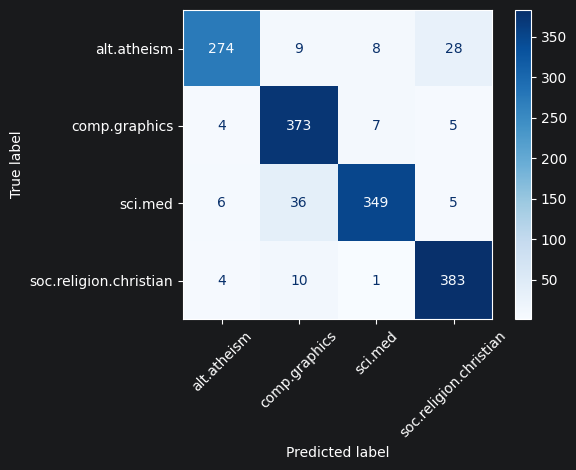

In [23]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Predict using the optimized model
y_pred = grid_search.predict(twenty_test.data)

# Calculate the confusion matrix
cm = confusion_matrix(twenty_test.target, y_pred)

# Display it
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=twenty_test.target_names
)

disp.plot(cmap="Blues", xticks_rotation=45)
plt.tight_layout()
plt.show()


In [24]:
# CLASSIFICATION REPORT


from sklearn.metrics import classification_report

print(
    classification_report(
        twenty_test.target,
        y_pred,
        target_names=twenty_test.target_names
    )
)


                        precision    recall  f1-score   support

           alt.atheism       0.95      0.86      0.90       319
         comp.graphics       0.87      0.96      0.91       389
               sci.med       0.96      0.88      0.92       396
soc.religion.christian       0.91      0.96      0.94       398

              accuracy                           0.92      1502
             macro avg       0.92      0.92      0.92      1502
          weighted avg       0.92      0.92      0.92      1502



### 1.5 Predict some sentences
Type some sentences and check if they are predicted correctly.

In [25]:
# Select the best model from GridSearchCV
best_model = grid_search.best_estimator_

# Write new sentences
docs_new = ["Doctors discovered a new treatment for cancer.",
            "How can I create 3D graphics using Python?",
            "Christians believe in God and Jesus Christ."
            ]

# Predict the categories
predicted = best_model.predict(docs_new)

# Display the results
for doc, category in zip(docs_new, predicted):
    print(doc, "=>", twenty_train.target_names[category])

Doctors discovered a new treatment for cancer. => sci.med
How can I create 3D graphics using Python? => comp.graphics
Christians believe in God and Jesus Christ. => soc.religion.christian


**Prediction confidence**

We can also ask the classifier for estimated class probabilities.

In [26]:

# Predict class probabilities
probabilities = best_model.predict_proba(docs_new)

for doc, probs in zip(docs_new, probabilities):
    print("\nSentence:", doc)

    for category, probability in zip(
        best_model.classes_, probs
    ):
        print(
            twenty_train.target_names[category],
            ":",
            round(probability, 3)
        )



Sentence: Doctors discovered a new treatment for cancer.
alt.atheism : 0.001
comp.graphics : 0.033
sci.med : 0.961
soc.religion.christian : 0.005

Sentence: How can I create 3D graphics using Python?
alt.atheism : 0.0
comp.graphics : 0.998
sci.med : 0.001
soc.religion.christian : 0.001

Sentence: Christians believe in God and Jesus Christ.
alt.atheism : 0.001
comp.graphics : 0.001
sci.med : 0.0
soc.religion.christian : 0.999


For each sentence, this returns a probability estimate for every category. The probabilities sum to 1, although they are not necessarily perfectly calibrated measures of confidence.

## To go further...

Other more advanced word embedding methods can be found in recent literature, and some are available in other packages, or online in trainable or pretrained versions. 
Those include static embeddings: (see word2vec, GloVe, fastText) and context dynamic embeddings: (Transformers, BERT, GPT, ...).

A few python libraries I can recommend you look up if you're interested: `nltk`, `gensim`, the huggingface libraries, ...

## Appendix: Text wrangling and preprocessing

In practice, textual datasets are rarely clean nor well structured, and often need some wrangling and preprocessing to be used effectively. 

Furthermore, depending on the specific task and context at hand, there are often other tailor-made transformations that can prove usefull as an addition or a replacement to normalization. (E.g. the way you would like to handle the `@`symbol might differ between e-mail and social media data. Or there might be specific groups of words that have similar meaning in general, but whose differentiation is important in a specific context.)

Additionally to vectorisation, manual feature extraction can also prove useful. For example the number of exclamation marks, the number of ALL CAPS WORDS, or the average word per sentence ratio might give additional information on the tone or sentiment of written text, depending on the context and model.

Here are a few basic string methods that can come in handy for those scenarios.

In [27]:
import string

In [28]:
text = "Hi there!"
text

'Hi there!'

In [29]:
text.replace("Hi","Hello")

'Hello there!'

In [30]:
text.replace("!"," ! ")

'Hi there ! '

In [31]:
text.replace("e","")

'Hi thr!'

In [32]:
text.split(" ")

['Hi', 'there!']

In [33]:
text.lower()

'hi there!'

In [34]:
string.punctuation

'!"#$%&\'()*+,-./:;<=>?@[\\]^_`{|}~'

The few examples above are just to inspire you some ideas. There are many things you could think of to analyze and extract informative summaries from text data. The pandas `<pd.Series>.apply()` method can come in very handy with custom user-defined functions.

pd.Series also has a `str` subset of functions for text data. Here are a few dummy examples.

In [35]:
str_text = pd.DataFrame({"my_text":["Hi there!","My dog is cute.","i lost my wallet"]})
str_text

,my_text
0,Hi there!
1,My dog is cute.
2,i lost my wallet


In [36]:
str_text.my_text.str.capitalize()

0           Hi there!
1     My dog is cute.
2    I lost my wallet
Name: my_text, dtype: object

In [37]:
str_text.my_text.str.lower()

0           hi there!
1     my dog is cute.
2    i lost my wallet
Name: my_text, dtype: object

In [38]:
str_text.my_text.str.contains("y")

0    False
1     True
2     True
Name: my_text, dtype: bool

In [39]:
str_text.my_text.str.contains("my")

0    False
1    False
2     True
Name: my_text, dtype: bool

In [40]:
str_text.my_text.str.count("e")

0    2
1    1
2    1
Name: my_text, dtype: int64

In [41]:
str_text.my_text.str.replace("e","")

0            Hi thr!
1     My dog is cut.
2    i lost my wallt
Name: my_text, dtype: object

Many more examples in the pandas documentation.

For more complicated text processing procedures, one would usually turn to [**regular expressions**](https://en.wikipedia.org/wiki/Regular_expression), as a much more powerful tool. The [`re` module](https://docs.python.org/3/library/re.html) provides the base tools to work with regular expressions in python. Some `pandas`'s  `Series.str` methods above also accept regular expressions.

This goes beyond the scope of this seminar, but if you are interested:
- [Interactive RegEx tutorials](https://regexr.com/)
- [Another tutorial](https://www.w3schools.com/python/python_regex.asp)
- And many more...